# Measures of Position (Relative Standing)
### Percentiles, Quartiles, Deciles, Percentile Ranks, Z-Scores & Modified Z-Scores
> **Programme:** C-DAC PGCP-AI | **Course:** Data Analytics  
> **Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`)  
> **Date:** September 30, 2026

---

### The Fundamental Question: "Where Do I Stand?"
While **Measures of Central Tendency** locate the center of a distribution, and **Measures of Dispersion** quantify how spread out values are, **Measures of Position** answer a distinctly different question:
> *"Where does a specific observation lie relative to the entire cohort or distribution?"*

* **The Raw Score Trap:**
  Suppose an employee receives an annual sales performance bonus based on a score of **82 out of 100**.
  * If the department average is **62** with standard deviation **5**, an 82 is **4 standard deviations above average** (Top 0.01% of all performers!).
  * If the department average is **88** with standard deviation **2**, that exact same score of 82 places the employee in the **bottom 0.1%**!

Without measures of relative standing, raw numbers lack actionable business context.

---

### Key Measures Covered in this Laboratory:
1. **Percentiles ($P_k$):** Dividing sorted data into 100 equal parts.
2. **Quartiles ($Q_1, Q_2, Q_3$):** Dividing into 4 equal quarters; Five-Number summary & Boxplots.
3. **Deciles & Quintiles ($D_1 \dots D_9$):** Socioeconomic & credit risk segmentation.
4. **Percentile Rank:** Computing the relative standing of an arbitrary score (inverse percentile).
5. **Standard Score ($Z$-Score):** Number of standard deviations away from the mean ($Z = rac{x - \mu}{\sigma}$).
6. **Modified $Z$-Score ($M_i$):** Robust outlier detection using Median and MAD, resistant to extreme masking.
7. **Cross-Scale Comparison:** Comparing metrics measured in completely different units.


In [1]:
# Setup and Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import math

# Styling configuration
plt.style.use('seaborn_v0_8_white' if 'seaborn_v0_8_white' in plt.style.available else 'default')
np.random.seed(42)

print("Environment configured successfully!")
print("NumPy version   :", np.__version__)
print("Pandas version  :", pd.__version__)


Environment configured successfully!
NumPy version   : 2.4.6
Pandas version  : 2.2.3


---
## 1. Percentiles ($P_k$)

* **Definition:** The $k$-th percentile ($P_k$) is the value below which $k\%$ of the observations in a sorted distribution fall.
* **Notation:** $P_{10}, P_{25}, P_{50}, P_{75}, P_{90}, P_{99}$
* **Everyday Example:**
  * In competitive examinations (such as CAT, GATE, or JEE), scoring at the **99.5th percentile** does **not** mean you answered 99.5% of questions correctly. It means your score was higher than 99.5% of all candidates who appeared for the exam.
* **Mathematical Rank Index ($L$):**
  For a sorted dataset $X = [x_{(1)}, x_{(2)}, \dots, x_{(n)}]$:
  $$L = \frac{k}{100} \times (n - 1) + 1$$
  If $L$ is an integer, $P_k = x_{(L)}$. If $L$ has a fractional part $f$, linear interpolation between adjacent ranks is used:
  $$P_k = x_{(\lfloor L \rfloor)} + f \cdot \left( x_{(\lceil L \rceil)} - x_{(\lfloor L \rfloor)} \right)$$

* **Comparison across Python Libraries:**
  * Plain Python: Sorting + explicit rank interpolation.
  * `numpy.percentile(a, q, method='linear')`
  * `scipy.stats.scoreatpercentile(a, per)`
  * `pandas.Series.quantile(q)` (takes quantile $q \in [0, 1]$)


Percentile (k)  | Pure Python  | NumPy      | SciPy      | Pandas    
P_10            | 57.70        | 57.70      | 57.70      | 57.70     
P_25            | 67.25        | 67.25      | 67.25      | 67.25     
P_50            | 76.50        | 76.50      | 76.50      | 76.50     
P_75            | 88.50        | 88.50      | 88.50      | 88.50     
P_90            | 95.30        | 95.30      | 95.30      | 95.30     
P_95            | 98.10        | 98.10      | 98.10      | 98.10     
P_99            | 99.62        | 99.62      | 99.62      | 99.62     


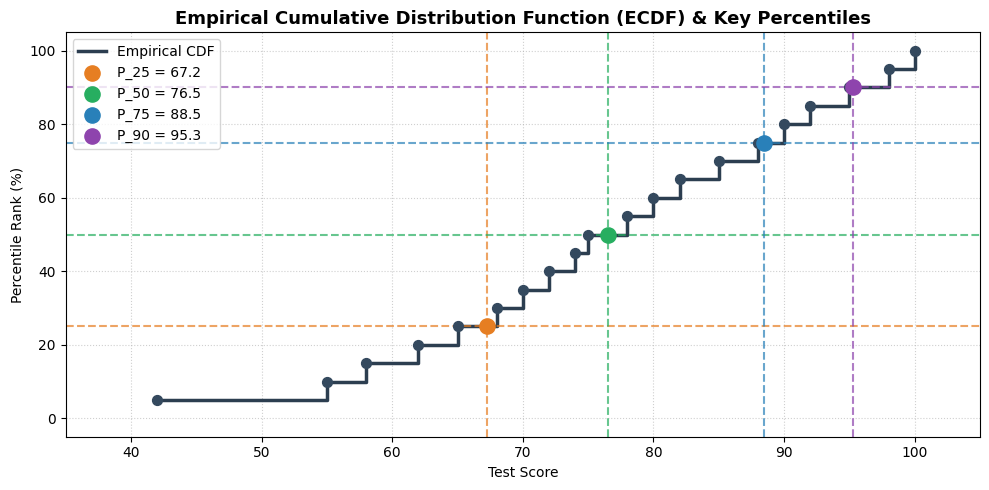

In [3]:
# 1. Percentiles: Naive implementation vs. Libraries

# Sample dataset: Test scores of 20 students
scores = [42, 55, 58, 62, 65, 68, 70, 72, 74, 75, 78, 80, 82, 85, 88, 90, 92, 95, 98, 100]

def pure_python_percentile(data, k):
    """Calculates k-th percentile using linear interpolation."""
    sorted_d = sorted(data)
    n = len(sorted_d)
    if n == 0:
        return None
    rank = (k / 100.0) * (n - 1)
    low_idx = int(math.floor(rank))
    high_idx = int(math.ceil(rank))
    fraction = rank - low_idx
    return sorted_d[low_idx] + fraction * (sorted_d[high_idx] - sorted_d[low_idx])

# Evaluate key percentiles
k_values = [10, 25, 50, 75, 90, 95, 99]

print("=" * 68)
print(f"{'Percentile (k)':<15} | {'Pure Python':<12} | {'NumPy':<10} | {'SciPy':<10} | {'Pandas':<10}")
print("=" * 68)

series_scores = pd.Series(scores)
for k in k_values:
    p_py = pure_python_percentile(scores, k)
    p_np = np.percentile(scores, k)
    p_sp = stats.scoreatpercentile(scores, k)
    p_pd = series_scores.quantile(k / 100.0)
    print(f"P_{k:<13} | {p_py:<12.2f} | {p_np:<10.2f} | {p_sp:<10.2f} | {p_pd:<10.2f}")
print("=" * 68)

# Visualizing Percentiles via Empirical Cumulative Distribution Function (ECDF)
sorted_scores = np.sort(scores)
ecdf = np.arange(1, len(sorted_scores) + 1) / len(sorted_scores) * 100.0

plt.figure(figsize=(10, 5))
plt.step(sorted_scores, ecdf, where='post', color='#2c3e50', lw=2.5, label='Empirical CDF')
plt.scatter(sorted_scores, ecdf, color='#34495e', s=50, zorder=4)

# Highlight key percentiles
highlight_k = [25, 50, 75, 90]
colors = ['#e67e22', '#27ae60', '#2980b9', '#8e44ad']

for k, c in zip(highlight_k, colors):
    val = np.percentile(scores, k)
    plt.axhline(k, color=c, linestyle='--', alpha=0.7)
    plt.axvline(val, color=c, linestyle='--', alpha=0.7)
    plt.scatter([val], [k], color=c, s=120, zorder=5, label=f'P_{k} = {val:.1f}')

plt.title('Empirical Cumulative Distribution Function (ECDF) & Key Percentiles', fontweight='bold', fontsize=13)
plt.xlabel('Test Score')
plt.ylabel('Percentile Rank (%)')
plt.ylim(-5, 105)
plt.xlim(35, 105)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


---
## 2. Quartiles ($Q_1, Q_2, Q_3$), Deciles ($D_1 \dots D_9$) & Quintiles

Measures of position that slice sorted data into specific equal fractions are termed **fractiles**:

### A. Quartiles (4 Equal Quarters - 25% each)
* **First Quartile ($Q_1$ / Lower Quartile):** $25\text{th percentile}$. Splits bottom 25% from top 75%.
* **Second Quartile ($Q_2$ / Median):** $50\text{th percentile}$. Exactly cuts the dataset in half.
* **Third Quartile ($Q_3$ / Upper Quartile):** $75\text{th percentile}$. Splits bottom 75% from top 25%.
* **Interquartile Range (IQR):** $\text{IQR} = Q_3 - Q_1$ (captures the middle 50% spread).
* **Semi-Interquartile Range (Quartile Deviation):** $\text{QD} = \frac{Q_3 - Q_1}{2}$.

### B. Deciles (10 Equal Tenths - 10% each)
* $D_1 = P_{10}, D_2 = P_{20}, \dots, D_5 = P_{50} (\text{Median}), \dots, D_9 = P_{90}$.
* **Banking Application:** Credit risk models divide applicants into 10 risk deciles ($D_1$ being lowest credit risk, $D_{10}$ highest probability of default).

### C. Quintiles (5 Equal Fifths - 20% each)
* Splits data into 20% bands ($Q_{uin1} = P_{20}, Q_{uin2} = P_{40}, \dots$).
* **Economics Application:** Government census and tax reports segment national household income into quintiles (Lowest 20% to Top 20%).

### D. The Five-Number Summary & Tukey's Boxplot
A standard summary consisting of:
$$\text{Minimum}, \quad Q_1, \quad \text{Median } (Q_2), \quad Q_3, \quad \text{Maximum}$$
* **Inner Fences:** $[Q_1 - 1.5 \times \text{IQR}, \; Q_3 + 1.5 \times \text{IQR}]$. Values outside are flagged as **outliers**.


Dataset Size (N)             : 20
Minimum Value                : $15
Q1 (25th Percentile)         : $31.50
Q2 (Median / 50th Percentile): $43.50
Q3 (75th Percentile)         : $61.25
Maximum Value                : $240
IQR (Q3 - Q1)                : $29.75
Tukey Lower Fence (Q1 - 1.5*IQR): $-13.12
Tukey Upper Fence (Q3 + 1.5*IQR): $105.88
Deciles (D1 to D9): [np.float64(24.7), np.float64(29.6), np.float64(34.1), np.float64(39.2), np.float64(43.5), np.float64(48.8), np.float64(56.5), np.float64(66.0), np.float64(88.5)]


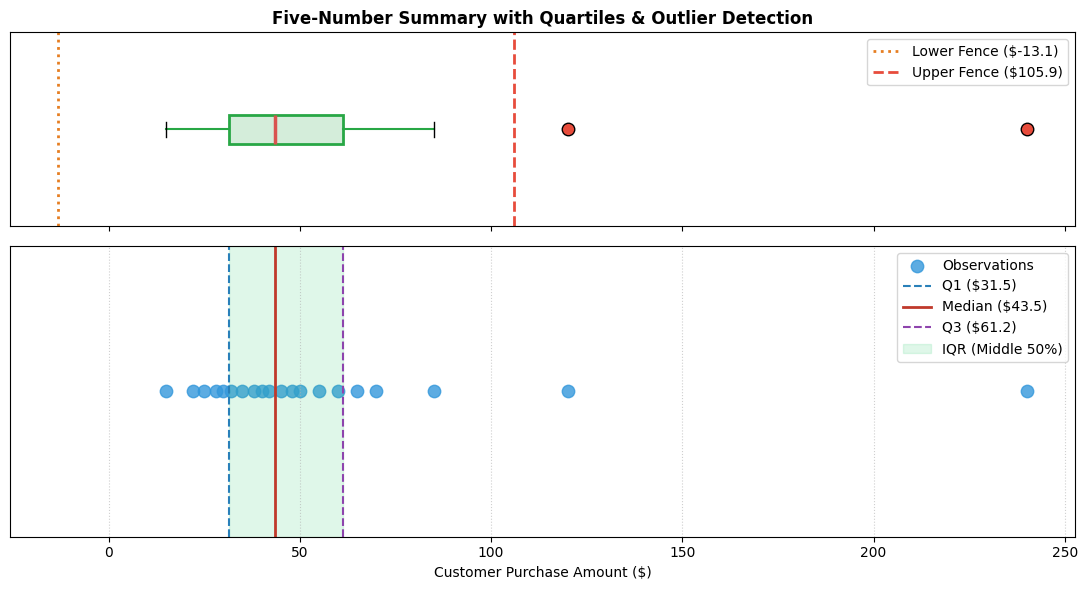

In [5]:
# 2. Quartiles, Deciles and Five-Number Summary
customer_purchases = [15, 22, 25, 28, 30, 32, 35, 38, 40, 42, 45, 48, 50, 55, 60, 65, 70, 85, 120, 240]

q1 = np.percentile(customer_purchases, 25)
q2 = np.percentile(customer_purchases, 50)
q3 = np.percentile(customer_purchases, 75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Deciles
deciles = [np.percentile(customer_purchases, d * 10) for d in range(1, 10)]

print("=" * 60)
print(f"Dataset Size (N)             : {len(customer_purchases)}")
print(f"Minimum Value                : ${min(customer_purchases)}")
print(f"Q1 (25th Percentile)         : ${q1:.2f}")
print(f"Q2 (Median / 50th Percentile): ${q2:.2f}")
print(f"Q3 (75th Percentile)         : ${q3:.2f}")
print(f"Maximum Value                : ${max(customer_purchases)}")
print(f"IQR (Q3 - Q1)                : ${iqr:.2f}")
print(f"Tukey Lower Fence (Q1 - 1.5*IQR): ${lower_fence:.2f}")
print(f"Tukey Upper Fence (Q3 + 1.5*IQR): ${upper_fence:.2f}")
print("=" * 60)
print("Deciles (D1 to D9):", [round(d, 1) for d in deciles])
print("=" * 60)

# Visualizing Five-Number Summary and Outlier Fences
fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(11, 6), sharex=True, 
                                      gridspec_kw={'height_ratios': [0.4, 0.6]})

# Boxplot
bp = ax_box.boxplot(customer_purchases, vert=False, patch_artist=True,
                    boxprops=dict(facecolor='#d4edda', color='#28a745', lw=2),
                    medianprops=dict(color='#d9534f', lw=2.5),
                    whiskerprops=dict(color='#28a745', lw=1.5),
                    flierprops=dict(marker='o', markerfacecolor='#e74c3c', markersize=9, markeredgecolor='black'))

ax_box.axvline(lower_fence, color='#e67e22', linestyle=':', lw=2, label=f'Lower Fence (${lower_fence:.1f})')
ax_box.axvline(upper_fence, color='#e74c3c', linestyle='--', lw=2, label=f'Upper Fence (${upper_fence:.1f})')
ax_box.set_yticks([])
ax_box.set_title('Five-Number Summary with Quartiles & Outlier Detection', fontweight='bold', fontsize=12)
ax_box.legend(loc='upper right')

# Scatter / Distribution
ax_hist.scatter(customer_purchases, [1]*len(customer_purchases), color='#3498db', s=80, alpha=0.8, label='Observations')
ax_hist.axvline(q1, color='#2980b9', linestyle='--', label=f'Q1 (${q1:.1f})')
ax_hist.axvline(q2, color='#c0392b', linestyle='-', lw=2, label=f'Median (${q2:.1f})')
ax_hist.axvline(q3, color='#8e44ad', linestyle='--', label=f'Q3 (${q3:.1f})')
ax_hist.axvspan(q1, q3, color='#2ecc71', alpha=0.15, label='IQR (Middle 50%)')

ax_hist.set_xlabel('Customer Purchase Amount ($)')
ax_hist.set_yticks([])
ax_hist.legend(loc='upper right')
ax_hist.grid(axis='x', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


---
## 3. Percentile Rank (Percentile of Score)

* **Definition:** The **Percentile Rank** of a specific score $x$ is the percentage of all scores in the dataset that are equal to or lower than $x$.
* **Contrast:**
  * **Percentile:** Input is percentage (e.g., 90%), output is a value (e.g., 85 marks).
  * **Percentile Rank:** Input is a value (e.g., 85 marks), output is the percentage rank (e.g., 90%).

* **Mathematical Formula:**
  $$\text{Percentile Rank}(x) = \left( \frac{\text{Count}(x_i < x) + 0.5 \times \text{Count}(x_i = x)}{n} \right) \times 100\%$$
  *Adding $0.5 \times \text{Count}(x_i = x)$ ensures the observation splits ties symmetrically.*

* **SciPy Function:**
  `scipy.stats.percentileofscore(a, score, kind='rank')`
  * `kind='rank'`: Average percentage of scores lower than or equal to score (handles ties cleanly).
  * `kind='weak'`: Percentage of scores $\le$ score.
  * `kind='strict'`: Percentage of scores $<$ score.
  * `kind='mean'`: Average of weak and strict (standard textbook formula above).


Target Score | Pure Python  | SciPy (mean) | SciPy (weak) | Interpretation
60           | 10.0        % | 10.0        % | 13.3        % | Outperforms 10.0% of students
75           | 46.7        % | 46.7        % | 53.3        % | Outperforms 46.7% of students
82           | 63.3        % | 63.3        % | 66.7        % | Outperforms 63.3% of students
95           | 96.7        % | 96.7        % | 100.0       % | Outperforms 96.7% of students


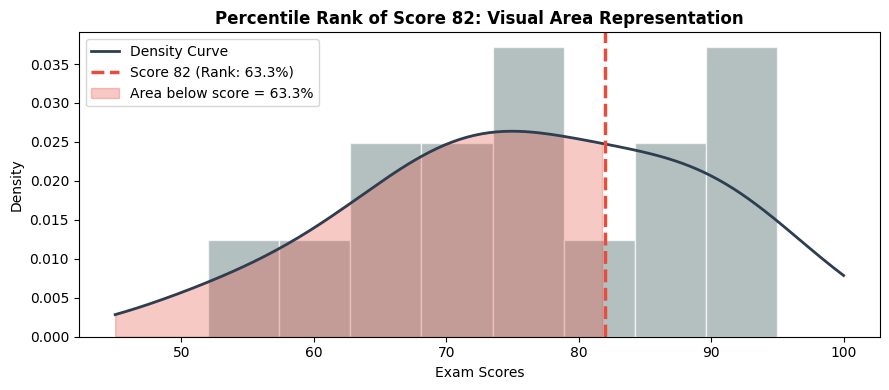

In [7]:
# 3. Percentile Rank: Finding Relative Standing of Specific Scores
class_scores = [52, 60, 65, 68, 70, 72, 75, 75, 78, 82, 85, 88, 90, 92, 95]

def pure_percentile_rank(data, score):
    """Calculates percentile rank using the standard half-tie formula."""
    less_count = sum(1 for x in data if x < score)
    equal_count = sum(1 for x in data if x == score)
    return ((less_count + 0.5 * equal_count) / len(data)) * 100.0

test_queries = [60, 75, 82, 95]

print("=" * 70)
print(f"{'Target Score':<12} | {'Pure Python':<12} | {'SciPy (mean)':<12} | {'SciPy (weak)':<12} | {'Interpretation'}")
print("=" * 70)

for score in test_queries:
    pr_py = pure_percentile_rank(class_scores, score)
    pr_sp_mean = stats.percentileofscore(class_scores, score, kind='mean')
    pr_sp_weak = stats.percentileofscore(class_scores, score, kind='weak')
    
    interp = f"Outperforms {pr_py:.1f}% of students"
    print(f"{score:<12} | {pr_py:<12.1f}% | {pr_sp_mean:<12.1f}% | {pr_sp_weak:<12.1f}% | {interp}")
print("=" * 70)

# Visualizing Percentile Rank on the Class Distribution
plt.figure(figsize=(9, 4))
plt.hist(class_scores, bins=8, color='#95a5a6', edgecolor='white', alpha=0.7, density=True)
kde = stats.gaussian_kde(class_scores)
x_vals = np.linspace(45, 100, 200)
plt.plot(x_vals, kde(x_vals), color='#2c3e50', lw=2, label='Density Curve')

# Plot test candidate at 82
target = 82
target_pr = pure_percentile_rank(class_scores, target)
plt.axvline(target, color='#e74c3c', lw=2.5, linestyle='--', label=f'Score {target} (Rank: {target_pr:.1f}%)')
plt.fill_between(x_vals[x_vals <= target], kde(x_vals[x_vals <= target]), color='#e74c3c', alpha=0.3, 
                 label=f'Area below score = {target_pr:.1f}%')

plt.title('Percentile Rank of Score 82: Visual Area Representation', fontweight='bold')
plt.xlabel('Exam Scores')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()


---
## 4. Standard Score ($Z$-Score)

* **Definition:** The $Z$-score measures the number of standard deviations a data point lies above or below the distribution mean.
* **Mathematical Notation:**
  $$Z = \frac{X - \mu}{\sigma} \quad (\text{Population}), \qquad z = \frac{x - \bar{x}}{s} \quad (\text{Sample})$$

* **Pronunciation & Interpretation:**
  * $z = 0$: Exactly at the mean.
  * $z = +1.5$: "One and a half standard deviations above the average."
  * $z = -2.3$: "2.3 standard deviations below the average."

* **Properties of the Standardized Distribution:**
  * Mean of $Z$-scores is always **$0$** ($\bar{z} = 0$).
  * Standard deviation of $Z$-scores is always **$1$** ($s_z = 1$).
  * Unitless metric (allows comparing kilograms to dollars to exam marks).

* **The Empirical Rule (68-95-99.7%):**
  For approximately bell-shaped (Normal) distributions:
  * $\approx 68.27\%$ of values lie within $[-1\sigma, \; +1\sigma]$
  * $\approx 95.45\%$ of values lie within $[-2\sigma, \; +2\sigma]$
  * $\approx 99.73\%$ of values lie within $[-3\sigma, \; +3\sigma]$
  * **Outlier Rule of Thumb:** Any point where $|Z| > 3.0$ is an extreme outlier.


Revenue Mean (x-bar)  : $587.14
Revenue Std Dev (s)   : $120.09
Revenue ($)  | Z-Score (Python)   | Z-Score (SciPy)  | Outlier Status
$450         | -1.142             | -1.142           | Normal Variation
$480         | -0.892             | -0.892           | Normal Variation
$510         | -0.642             | -0.642           | Normal Variation
$520         | -0.559             | -0.559           | Normal Variation
$530         | -0.476             | -0.476           | Normal Variation
$550         | -0.309             | -0.309           | Normal Variation
$560         | -0.226             | -0.226           | Normal Variation
$570         | -0.143             | -0.143           | Normal Variation
$590         | 0.024              | 0.024            | Normal Variation
$600         | 0.107              | 0.107            | Normal Variation
$610         | 0.190              | 0.190            | Normal Variation
$630         | 0.357              | 0.357            | Normal Variation
$6

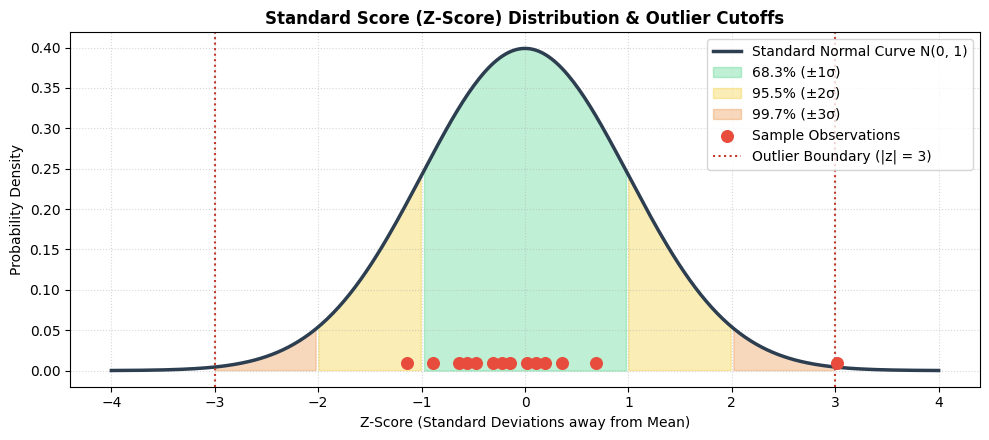

In [9]:
# 4. Z-Score Calculation & Normal Bell Curve Mapping
daily_revenues = [450, 480, 510, 520, 530, 550, 560, 570, 590, 600, 610, 630, 670, 950]

mean_rev = np.mean(daily_revenues)
std_rev = np.std(daily_revenues, ddof=1) # sample standard deviation

# Pure Python Z-scores
z_scores_py = [(x - mean_rev) / std_rev for x in daily_revenues]

# SciPy Z-scores
z_scores_sp = stats.zscore(daily_revenues, ddof=1)

print("=" * 65)
print(f"Revenue Mean (x-bar)  : ${mean_rev:.2f}")
print(f"Revenue Std Dev (s)   : ${std_rev:.2f}")
print("=" * 65)
print(f"{'Revenue ($)':<12} | {'Z-Score (Python)':<18} | {'Z-Score (SciPy)':<16} | {'Outlier Status'}")
print("=" * 65)

for rev, z in zip(daily_revenues, z_scores_sp):
    status = "Extreme Outlier (|z| > 2.5)" if abs(z) > 2.5 else "Normal Variation"
    print(f"${rev:<11} | {z:<18.3f} | {z:<16.3f} | {status}")
print("=" * 65)

# Standard Normal Bell Curve with Z-Score Boundaries
x_axis = np.linspace(-4, 4, 300)
pdf_vals = stats.norm.pdf(x_axis, 0, 1)

plt.figure(figsize=(10, 4.5))
plt.plot(x_axis, pdf_vals, color='#2c3e50', lw=2.5, label='Standard Normal Curve N(0, 1)')

# Shading standard deviation zones
plt.fill_between(x_axis, pdf_vals, where=(x_axis >= -1) & (x_axis <= 1), color='#2ecc71', alpha=0.3, label='68.3% (±1σ)')
plt.fill_between(x_axis, pdf_vals, where=((x_axis >= -2) & (x_axis < -1)) | ((x_axis > 1) & (x_axis <= 2)), 
                 color='#f1c40f', alpha=0.3, label='95.5% (±2σ)')
plt.fill_between(x_axis, pdf_vals, where=((x_axis >= -3) & (x_axis < -2)) | ((x_axis > 2) & (x_axis <= 3)), 
                 color='#e67e22', alpha=0.3, label='99.7% (±3σ)')

# Plot sample z-scores as points on baseline
plt.scatter(z_scores_sp, np.zeros_like(z_scores_sp) + 0.01, color='#e74c3c', s=70, zorder=5, label='Sample Observations')

plt.title('Standard Score (Z-Score) Distribution & Outlier Cutoffs', fontweight='bold', fontsize=12)
plt.xlabel('Z-Score (Standard Deviations away from Mean)')
plt.ylabel('Probability Density')
plt.axvline(-3, color='#c0392b', linestyle=':', label='Outlier Boundary (|z| = 3)')
plt.axvline(3, color='#c0392b', linestyle=':')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 5. Modified $Z$-Score ($M_i$) — Robust Measure of Position

### The Masking / Swamping Trap of the Standard $Z$-Score:
* The standard $Z$-score has a fatal vulnerability: it uses the **sample mean** ($\bar{x}$) and **sample standard deviation** ($s$).
* Both $\bar{x}$ and $s$ are **non-robust**: an extreme outlier violently inflates $s$.
* **The Paradox (Masking):** Because the outlier inflates the denominator ($s$), its own $Z$-score is artificially shrunken! Furthermore, valid neighboring points have their $Z$-scores compressed, causing actual anomalies to go undetected.

---

### The Boris Iglewicz & David Hoaglin (1993) Formulation:
The **Modified $Z$-score ($M_i$)** replaces the mean with the **median** ($\tilde{x}$) and the standard deviation with the **Median Absolute Deviation (MAD)**:

$$M_i = \frac{0.6745 \cdot (x_i - \tilde{x})}{\text{MAD}}$$

Where:
* $\tilde{x} = \text{median}(X)$
* $\text{MAD} = \text{median}(|x_i - \tilde{x}|)$
* **Why the constant $0.6745$?**
  For a standard normal distribution, the 75th percentile is $0.6745\sigma$. Hence:
  $$E[\text{MAD}] = \Phi^{-1}(0.75) \cdot \sigma \approx 0.6745 \cdot \sigma \implies \frac{\text{MAD}}{0.6745} \approx \sigma$$
  Multiplying by $0.6745$ standardizes the scale so that $M_i$ behaves identically to a standard $Z$-score under a normal distribution!

* **Outlier Decision Threshold:**
  $$\text{Observation } x_i \text{ is flagged as an outlier if } |M_i| > 3.5$$


Mean: 48.90°C | Std Dev: 89.91°C (Severely inflated by 320°C!)
Median: 21.90°C | MAD: 0.30°C (Completely unaffected!)
Observation  | Standard Z   | Outlier (|z|>3)?   | Modified Z   | Outlier (|M|>3.5)?
21.0         | -0.31        | Passed             | -2.02        | Passed
21.5         | -0.30        | Passed             | -0.90        | Passed
22.0         | -0.30        | Passed             | 0.22         | Passed
21.8         | -0.30        | Passed             | -0.22        | Passed
22.2         | -0.30        | Passed             | 0.67         | Passed
21.4         | -0.31        | Passed             | -1.12        | Passed
21.9         | -0.30        | Passed             | 0.00         | Passed
22.1         | -0.30        | Passed             | 0.45         | Passed
21.7         | -0.30        | Passed             | -0.45        | Passed
22.3         | -0.30        | Passed             | 0.90         | Passed
320.0        | 3.02         | FLAGGED            | 670.23       | F

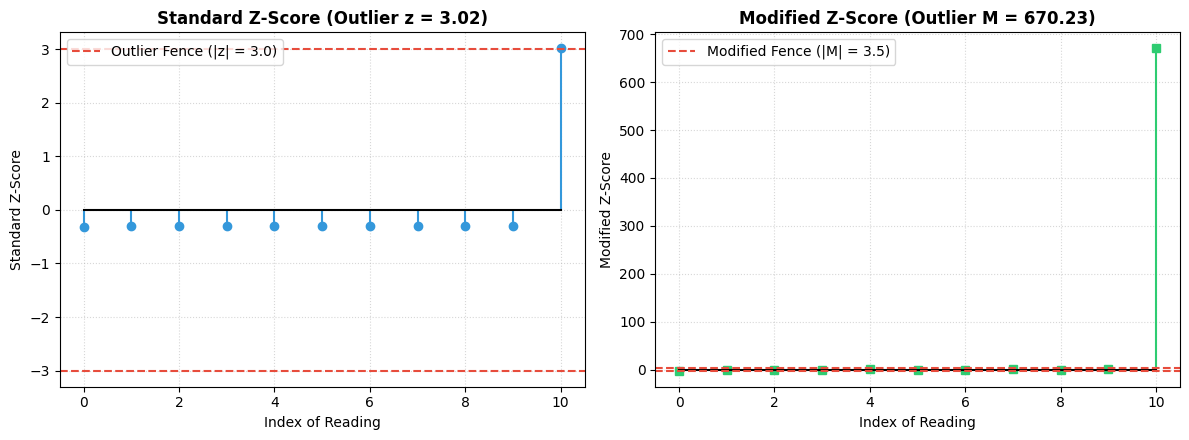

In [11]:
# 5. Standard Z-Score vs. Modified Z-Score: The Masking Test

# Clean sensor temperatures with one massive anomaly (sensor glitch at 320°C)
readings = np.array([21.0, 21.5, 22.0, 21.8, 22.2, 21.4, 21.9, 22.1, 21.7, 22.3, 320.0])

# Standard Z-Score
mean_val = np.mean(readings)
std_val = np.std(readings, ddof=1)
standard_z = (readings - mean_val) / std_val

# Modified Z-Score
median_val = np.median(readings)
mad_val = stats.median_abs_deviation(readings, scale=1.0) # raw MAD
modified_z = (0.6745 * (readings - median_val)) / mad_val

print("=" * 75)
print(f"Mean: {mean_val:.2f}°C | Std Dev: {std_val:.2f}°C (Severely inflated by 320°C!)")
print(f"Median: {median_val:.2f}°C | MAD: {mad_val:.2f}°C (Completely unaffected!)")
print("=" * 75)
print(f"{'Observation':<12} | {'Standard Z':<12} | {'Outlier (|z|>3)?':<18} | {'Modified Z':<12} | {'Outlier (|M|>3.5)?'}")
print("=" * 75)

for x, sz, mz in zip(readings, standard_z, modified_z):
    sz_flag = "FLAGGED" if abs(sz) > 3.0 else "Passed"
    mz_flag = "FLAGGED" if abs(mz) > 3.5 else "Passed"
    print(f"{x:<12.1f} | {sz:<12.2f} | {sz_flag:<18} | {mz:<12.2f} | {mz_flag}")
print("=" * 75)

# Visual Comparison of Standard Z vs Modified Z
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

indices = np.arange(len(readings))

# Subplot 1: Standard Z
ax1.stem(indices, standard_z, basefmt='k-', linefmt='#3498db', markerfmt='o')
ax1.axhline(3.0, color='#e74c3c', linestyle='--', label='Outlier Fence (|z| = 3.0)')
ax1.axhline(-3.0, color='#e74c3c', linestyle='--')
ax1.set_title(f'Standard Z-Score (Outlier z = {standard_z[-1]:.2f})', fontweight='bold')
ax1.set_xlabel('Index of Reading')
ax1.set_ylabel('Standard Z-Score')
ax1.grid(True, linestyle=':', alpha=0.5)
ax1.legend()

# Subplot 2: Modified Z
ax2.stem(indices, modified_z, basefmt='k-', linefmt='#2ecc71', markerfmt='s')
ax2.axhline(3.5, color='#e74c3c', linestyle='--', label='Modified Fence (|M| = 3.5)')
ax2.axhline(-3.5, color='#e74c3c', linestyle='--')
ax2.set_title(f'Modified Z-Score (Outlier M = {modified_z[-1]:.2f})', fontweight='bold')
ax2.set_xlabel('Index of Reading')
ax2.set_ylabel('Modified Z-Score')
ax2.grid(True, linestyle=':', alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()


---
## 6. Comparing Relative Standing Across Different Scales

### Practical Scenario: Evaluating Student Performance Across Disparate Subjects
Suppose a student receives the following grades in two challenging courses:
* **Machine Learning:** Raw Score = **84 / 100**
  * Class Mean $\mu = 70$, Standard Deviation $\sigma = 7$
* **Advanced Mathematics:** Raw Score = **76 / 100**
  * Class Mean $\mu = 60$, Standard Deviation $\sigma = 4$

**Question:** In which subject did the student demonstrate superior relative academic standing?

* **Raw Comparison:** $84 > 76 \implies$ Naively appears better in Machine Learning.
* **Standardized Comparison ($Z$-Score):**
  $$Z_{\text{ML}} = \frac{84 - 70}{7} = \frac{14}{7} = \mathbf{+2.00} \quad (\text{Top } 2.28\%)$$
  $$Z_{\text{Math}} = \frac{76 - 60}{4} = \frac{16}{4} = \mathbf{+4.00} \quad (\text{Top } 0.003\%)$$

**Conclusion:** In Advanced Mathematics, the student performed **4 standard deviations above the class**, representing an extraordinary achievement compared to Machine Learning.


             Subject  Raw Score  Class Mean (μ)  Class Std (σ)  Z-Score  Norm Percentile (%)
    Machine Learning         84              70              7      2.0                97.72
Advanced Mathematics         76              60              4      4.0               100.00
    Database Systems         90              85              5      1.0                84.13
     Cloud Computing         65              62              3      1.0                84.13


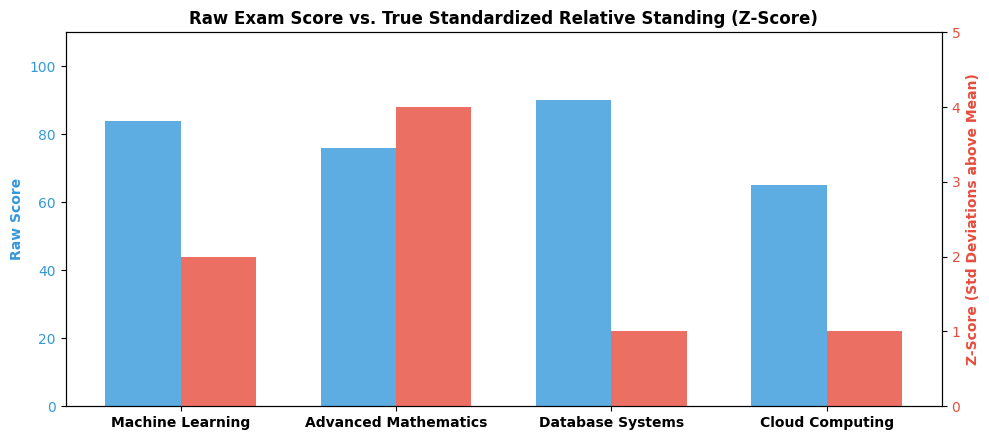

In [13]:
# 6. Cross-Subject Academic Performance Comparison
subjects = ['Machine Learning', 'Advanced Mathematics', 'Database Systems', 'Cloud Computing']
student_scores = [84, 76, 90, 65]
class_means    = [70, 60, 85, 62]
class_stds     = [ 7,  4,  5,  3]

# Compute Z-Scores and Percentiles under Normality
z_scores = [(score - mu) / sigma for score, mu, sigma in zip(student_scores, class_means, class_stds)]
percentiles = [stats.norm.cdf(z) * 100.0 for z in z_scores]

df_comparison = pd.DataFrame({
    'Subject': subjects,
    'Raw Score': student_scores,
    'Class Mean (μ)': class_means,
    'Class Std (σ)': class_stds,
    'Z-Score': np.round(z_scores, 2),
    'Norm Percentile (%)': np.round(percentiles, 2)
})

print("=" * 80)
print(df_comparison.to_string(index=False))
print("=" * 80)

# Visualizing the contrast between Raw Scores and Standardized Position
fig, ax1 = plt.subplots(figsize=(10, 4.5))

x_indices = np.arange(len(subjects))
bar_width = 0.35

color1 = '#3498db'
ax1.bar(x_indices - bar_width/2, student_scores, bar_width, color=color1, alpha=0.8, label='Raw Score (0-100)')
ax1.set_ylabel('Raw Score', color=color1, fontweight='bold')
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 110)

ax2 = ax1.twinx()
color2 = '#e74c3c'
ax2.bar(x_indices + bar_width/2, z_scores, bar_width, color=color2, alpha=0.8, label='Standard Z-Score')
ax2.set_ylabel('Z-Score (Std Deviations above Mean)', color=color2, fontweight='bold')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.set_ylim(0, 5)

ax1.set_xticks(x_indices)
ax1.set_xticklabels(subjects, fontweight='bold')
plt.title('Raw Exam Score vs. True Standardized Relative Standing (Z-Score)', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()


---
## 7. Master Comparison & Decision Matrix

| Measure of Position | Mathematical Formula | Units / Range | Resistant to Outliers? | Ideal Use Case |
| :--- | :---: | :---: | :---: | :--- |
| **Percentile ($P_k$)** | $P_k = \text{Value at rank } \frac{k}{100}(n-1)+1$ | Same as data | **Yes** (non-parametric) | Competitive exams (CAT, GATE), SLA benchmarks (95th percentile latency). |
| **Quartiles ($Q_1, Q_2, Q_3$)** | $P_{25}, \; P_{50}, \; P_{75}$ | Same as data | **Yes** | Five-number summary, boxplot visualizations, IQR calculation. |
| **Deciles ($D_1 \dots D_9$)** | $P_{10}, \; P_{20}, \dots, P_{90}$ | Same as data | **Yes** | Banking risk tiers, decile income analysis, marketing propensity scores. |
| **Percentile Rank** | $\frac{\text{Count}(<x) + 0.5 \cdot \text{Count}(=x)}{n} \times 100$ | $0\% \text{ to } 100\%$ | **Yes** | Standardized testing reports, customer loyalty tiers. |
| **Standard $Z$-Score** | $z = \frac{x - \bar{x}}{s}$ | Unitless ($-\infty$ to $+\infty$) | **No** (vulnerable to masking) | Symmetric, bell-shaped distributions; cross-scale normalization. |
| **Modified $Z$-Score ($M_i$)** | $M_i = \frac{0.6745(x_i - \tilde{x})}{\text{MAD}}$ | Unitless ($-\infty$ to $+\infty$) | **Yes** (uses Median and MAD) | Heavy-tailed distributions, anomaly/fraud detection without masking. |

---

### Key Takeaways for Data Analysts:
1. **Never judge an observation by its raw magnitude alone:** Standardize or compute its percentile rank to assess real significance.
2. **Be mindful of ties:** Use the half-tie formula ($	ext{Count}(<) + 0.5 	imes 	ext{Count}(=)$) when calculating percentile ranks in discrete data.
3. **Beware the $Z$-score masking trap:** If your data contains extreme spikes, use **Modified $Z$-score** ($|M_i| > 3.5$) instead of standard $Z$-score ($|z| > 3.0$).
